# Cohomologie de groupe calculée — H¹, H² et extensions centrales

**Module :** Serre 100 — distillations exécutables des thèmes de Jean-Pierre Serre
**Niveau :** Arithmétique — groupes finis et modules
**Technologies :** Python stdlib (modules Z/nZ), matplotlib
**Durée estimée :** 45 minutes

## Objectifs d'Apprentissage

- [ ] Calculer les **1-cocycles** d'un module Z/n sur de petits groupes, et en déduire H¹(G, M)
- [ ] Calculer les **2-cocycles** par énumération exhaustive, et en déduire H²(G, M)
- [ ] **Refuter par la mesure** la loi « le groupe de cohomologie en degré 2 vaut toujours Z/2 »
- [ ] Reconnaître dans H²(C₂, Z/2) le **classificateur des extensions centrales** de C₂ (C₄ ou C₂ × C₂)

## Prérequis

- Carnet 05 (table de caracteres) — le vocabulaire des groupes finis et des homomorphismes
- Carnet 20 (Sylow) — les groupes finis vus comme groupes de permutations
- Notions de groupe, de module et d'action : le vocabulaire est repris ici, aucun prérequis de cohomologie

**Navigation :** Index (README.md) | Precedent : 20b-groupes-abeliens-finis

In [1]:
# Imports et posture du carnet
import itertools

import matplotlib.pyplot as plt

print("COHOMOLOGIE DE GROUPE -- TOUT EST ENUMERE")
print("=" * 62)
print("Un module M = Z/nZ sur lequel un groupe G agit.")
print("Les cocycles sont explicitement listes, puis quotientes par les coboundaires.")

COHOMOLOGIE DE GROUPE -- TOUT EST ENUMERE
Un module M = Z/nZ sur lequel un groupe G agit.
Les cocycles sont explicitement listes, puis quotientes par les coboundaires.


## Section 1 — Les groupes et les modules du carnet

On travaille sur cinq groupes finis, écrits **explicitement** (la loi de groupe est portée par la structure de données, pas par une table imprimée) :

| Groupe | Notation | Ordre | Pourquoi |
|---|---|---:|---|
| Cyclique | C₂, C₃, C₄ | 2, 3, 4 | les plus petits groupes non triviaux, et C₂ est le cas où H² classifie vraiment quelque chose |
| Klein | V₄ = C₂ × C₂ | 4 | abélien mais **non cyclique** : le multiplicateur de Schur y est non trivial |
| Symétrique | S₃ | 6 | un groupe non abélien, pour vérifier que la méthode ne dépend pas de l'abélianité |

Un **module** M = Z/nZ est muni d'une *action* de G : une fonction qui envoie `g` et `m` sur `g . m`. Deux actions sont utilisées :

- l'**action triviale**, où tout élément de G fixe M ;
- l'**action par le signe**, où l'élément « impair » agit par `m ↦ -m`. Elle est définie pour C₂ (le générateur est impair) et pour S₃ (la parité de la permutation).

Le signe d'un élément est stocké **dans le groupe** : c'est une propriété du groupe, pas de l'action, et il faut que ce soit un homomorphisme G → Z/2 pour que l'action soit légitime.

In [2]:
# Les groupes de travail, ecrits comme des structures de donnees explicites
def cyclique(n):
    """C_n : elements 0..n-1, addition modulo n. Le generateur 1 est impair."""
    return {"nom": "C%d" % n, "elements": list(range(n)),
            "mul": lambda a, b, n=n: (a + b) % n,
            "signe": lambda g, n=n: 0 if g == 0 else 1}


def klein():
    """V4 = C2 x C2 : elements (a, b), addition coordonnee modulo 2."""
    return {"nom": "V4", "elements": [(0, 0), (0, 1), (1, 0), (1, 1)],
            "mul": lambda a, b: tuple((x + y) % 2 for x, y in zip(a, b)),
            "signe": lambda g: 0}


def symetrique3():
    """S3 vu comme les permutations de {0, 1, 2} ; le signe est la parite."""
    perms = sorted(itertools.permutations(range(3)))

    def parite(g):
        inversions = sum(1 for i in range(3) for j in range(i + 1, 3) if g[i] > g[j])
        return inversions % 2

    return {"nom": "S3", "elements": perms,
            "mul": lambda a, b: tuple(a[i] for i in b),
            "signe": parite}


GROUPES = [cyclique(2), cyclique(3), cyclique(4), klein(), symetrique3()]


def action_triviale(g, m, M):
    """Action triviale : tout element du groupe fixe le module."""
    return m % M


def fabrique_action_signe(G):
    """L'action par le signe de G sur Z/nZ : l'element impair agit par negation."""
    signe = G["signe"]

    def action(g, m, M):
        return m % M if signe(g) % 2 == 0 else (-m) % M

    return action


print("Groupes utilises :")
for G in GROUPES:
    print("  %-4s -- %d elements" % (G["nom"], len(G["elements"])))

Groupes utilises :
  C2   -- 2 elements
  C3   -- 3 elements
  C4   -- 4 elements
  V4   -- 4 elements
  S3   -- 6 elements


## Section 2 — Les 1-cocycles, et H¹

Une fonction `c : G → M` est un **1-cocycle** (un *homomorphisme croisé*) quand

$$
c(gh) = c(g) + g \cdot c(h)
$$

pour tous `g, h` de G. L'ensemble de ces fonctions est stable par addition : c'est un groupe. Les **coboundaires** `c_m(g) = g . m - m` (pour `m` dans M) forment un sous-groupe de celui-ci, et le quotient `H¹(G, M)` est le groupe de cohomologie de degré 1.

L'indexation change avec le degré, et c'est là que se loge l'erreur la plus fréquente : en degré 1, `C⁰ = M`, le coboundaire est indexé par un **élément du module** (`m`), pas par une fonction `G → M` ; en degré 2, `C¹` est l'ensemble des fonctions `G → M`, et le coboundaire est indexé par une **1-cochaîne**. Compter les coboundaires, c'est compter des fonctions distinctes : deux `m` du module peuvent donner le même coboundaire, et c'est le nombre de coboundaires **distincts** qui entre dans le quotient.

La méthode est **exhaustive et non probabiliste** : on liste toutes les fonctions `G → M` (il y en a `|M|^|G|`), on ne garde que celles qui satisfont la condition, puis on regroupe les fonctions qui diffèrent d'un coboundaire.

In [3]:
# Enumeration des 1-cocycles et des coboundaires
def cocycles_degre1(G, M, action):
    """Les 1-cocycles c : G -> M, i.e. c(gh) = c(g) + g . c(h)."""
    elements, mul = G["elements"], G["mul"]
    solutions = []
    for valeurs in itertools.product(range(M), repeat=len(elements)):
        c = dict(zip(elements, valeurs))
        if all((c[mul(g, h)] - c[g] - action(g, c[h], M)) % M == 0
               for g in elements for h in elements):
            solutions.append(c)
    return solutions


def coboundaires_degre1(G, M, action):
    """Les coboundaires c_m(g) = g . m - m, pour m parcourant le module M.

    En degre 1, C^0 = M : le coboundaire est indexe par un element du
    module, pas par une fonction G -> M. On renvoie les coboundaires
    DISTINCTS, i.e. le sous-groupe B^1 : deux elements m, m' du module
    donnent le meme coboundaire quand m - m' est fixe par l'action.
    """
    elements = G["elements"]
    vus = {}
    for m in range(M):
        coboundaire = {g: (action(g, m, M) - m) % M for g in elements}
        vus.setdefault(tuple(coboundaire[g] for g in elements), coboundaire)
    return list(vus.values())


def classes_degre1(cocycles, coboundaires, M):
    """Les classes de H^1 : une classe = {cocycle + coboundaire}."""
    classes = {}
    for c in cocycles:
        cle = frozenset(tuple((c[g] + b[g]) % M for g in sorted(c)) for b in coboundaires)
        classes.setdefault(cle, c)
    return classes


print("H^1(G, Z/2Z) -- action triviale")
print("-" * 62)
H1 = {}
for G in GROUPES:
    cocycles = cocycles_degre1(G, 2, action_triviale)
    coboundaires = coboundaires_degre1(G, 2, action_triviale)
    classes = classes_degre1(cocycles, coboundaires, 2)
    H1[G["nom"]] = classes
    print("%-4s : |Z^1| = %3d | |B^1| = %3d | |H^1| = %d"
          % (G["nom"], len(cocycles), len(coboundaires), len(classes)))

H^1(G, Z/2Z) -- action triviale
--------------------------------------------------------------
C2   : |Z^1| =   2 | |B^1| =   1 | |H^1| = 2
C3   : |Z^1| =   1 | |B^1| =   1 | |H^1| = 1
C4   : |Z^1| =   2 | |B^1| =   1 | |H^1| = 2
V4   : |Z^1| =   4 | |B^1| =   1 | |H^1| = 4
S3   : |Z^1| =   2 | |B^1| =   1 | |H^1| = 2


### Interprétation — H¹ est le groupe des quotients

Le tableau se lit sans théorie supplémentaire : pour l'action triviale, `H¹(G, Z/2)` n'est autre chose que le groupe des homomorphismes de G dans Z/2 — c'est-à-dire l'ensemble des **quotients d'ordre 2** de G, un par quotient (plus le quotient trivial).

La colonne `|B¹| = 1` a sa lecture propre : sous l'action triviale, `c_m(g) = g . m - m = 0` pour **tout** `m` — tous les coboundaires se confondent avec le coboundaire nul. Le sous-groupe `B¹` est donc réduit à son élément neutre, le quotient ne retire rien, et `|H¹| = |Z¹|`.

- `|H¹(C₃, Z/2)| = 1` : C₃ n'a **aucun** quotient d'ordre 2 (3 est impair) ;
- `|H¹(V₄, Z/2)| = 4` : V₄ a **trois** quotients d'ordre 2, plus le quotient trivial ;
- `|H¹(S₃, Z/2)| = 2` : un seul quotient d'ordre 2, la signature.

Le point important : ce ne sont pas des nombres **affirmés**, ils sont **comptés**. Et le contrôle qui suit les confronte à un calcul qui ne partage aucune ligne de code avec l'énumération des cocycles.

In [4]:
# Controle croise : |H^1(G, Z/2)| contre le nombre de sous-groupes d'indice 2
def sous_groupes(G):
    """Tous les sous-groupes de G, par enumeration des parties et test de cloture."""
    elements = G["elements"]
    trouves = []
    for taille in range(1, len(elements) + 1):
        for partie in itertools.combinations(elements, taille):
            S = set(partie)
            if all(G["mul"](a, b) in S for a in S for b in S):
                trouves.append(S)
    return trouves


print("Controle croise mesure / mesure")
print("-" * 62)
print("Un homomorphisme G -> Z/2 non trivial correspond a un sous-groupe d'indice 2.")
print("On compte donc les sous-groupes d'indice 2 par enumeration des parties.")
print()
for G in GROUPES:
    ordre = len(G["elements"])
    indices2 = sum(1 for S in sous_groupes(G) if len(S) * 2 == ordre)
    attendu = 1 + indices2
    mesure = len(H1[G["nom"]])
    verdict = "OK" if mesure == attendu else "ECART"
    print("%-4s : |H^1| = %d  |  1 + #(sous-groupes d'indice 2) = 1 + %d = %d   [%s]"
          % (G["nom"], mesure, indices2, attendu, verdict))

Controle croise mesure / mesure
--------------------------------------------------------------
Un homomorphisme G -> Z/2 non trivial correspond a un sous-groupe d'indice 2.
On compte donc les sous-groupes d'indice 2 par enumeration des parties.

C2   : |H^1| = 2  |  1 + #(sous-groupes d'indice 2) = 1 + 1 = 2   [OK]
C3   : |H^1| = 1  |  1 + #(sous-groupes d'indice 2) = 1 + 0 = 1   [OK]
C4   : |H^1| = 2  |  1 + #(sous-groupes d'indice 2) = 1 + 1 = 2   [OK]
V4   : |H^1| = 4  |  1 + #(sous-groupes d'indice 2) = 1 + 3 = 4   [OK]
S3   : |H^1| = 2  |  1 + #(sous-groupes d'indice 2) = 1 + 1 = 2   [OK]


## Section 3 — Une action qui n'est pas triviale

L'action triviale masque l'essentiel de la cohomologie : les 1-cocycles ne sont alors que des homomorphismes. On reprend C₂ avec le module **Z/4Z** muni de l'**action par le signe** (le générateur agit par `m ↦ -m`).

Le calcul change de nature : la condition `c(s²) = c(s) + s . c(s)` devient `c(s²) = c(s) - c(s) = 0`, ce qui **impose** `c(s²) = 0` au lieu de laisser le choix libre.

In [5]:
# H^1(C2, Z/4Z) avec l'action par le signe
C2 = GROUPES[0]
action_signe_c2 = fabrique_action_signe(C2)
cocycles = cocycles_degre1(C2, 4, action_signe_c2)
coboundaires = coboundaires_degre1(C2, 4, action_signe_c2)
classes = classes_degre1(cocycles, coboundaires, 4)

print("H^1(C2, Z/4Z) -- action par le signe")
print("-" * 62)
print("|Z^1| = %d (1-cocycles trouves)" % len(cocycles))
print("|B^1| = %d (coboundaires distincts)" % len(coboundaires))
print("|H^1| = %d" % len(classes))
print()
print("Un representant par classe :")
for cle, c in classes.items():
    print("   c(e) = %d, c(s) = %d" % (c[C2["elements"][0]], c[C2["elements"][1]]))

H^1(C2, Z/4Z) -- action par le signe
--------------------------------------------------------------
|Z^1| = 4 (1-cocycles trouves)
|B^1| = 2 (coboundaires distincts)
|H^1| = 2

Un representant par classe :
   c(e) = 0, c(s) = 0
   c(e) = 0, c(s) = 1


### Interprétation — l'action change le compte, pas la méthode

La méthode est **la même** — énumérer, filtrer, quotienter — mais le résultat change : avec l'action triviale sur Z/2 on obtenait `|H¹(C₂, Z/2)| = 2`, avec l'action par le signe sur Z/4 on obtient un groupe d'ordre 2 également, mais **construit différemment** (les coboundaires ne sont plus triviaux : `c_m(s) = -2m`, qui vaut 2 modulo 4 pour `m` impair et 0 pour `m` pair — d'où les **deux** coboundaires distincts, `|B¹| = 2`).

C'est le sens de la formule de Serre dans *Cohomologie des groupes discrets* : le module et l'action font partie de l'objet, on ne cohomologise pas un groupe seul.

## Section 4 — Les 2-cocycles : H² par énumération exhaustive

Une fonction `f : G × G → M` est un **2-cocycle** quand, pour tous `g, h, k`,

$$
g \cdot f(h, k) - f(gh, k) + f(g, hk) - f(g, h) = 0
$$

Les **coboundaires** sont cette fois `f_m(g, h) = g . m(h) - m(gh) + m(g)`, et `H²(G, M)` est le quotient.

L'énumération est exhaustive et reste praticable : il y a `|M|^(|G|²)` candidats, soit `2^16 = 65 536` fonctions pour `|G| = 4` et `|M| = 2`. C'est ce qui permet de **refuter** une formule plutôt que de la confirmer.

In [6]:
# Enumeration exhaustive des 2-cocycles
def cocycles_degre2(G, M, action):
    """Les 2-cocycles f : G x G -> M, i.e. d^2 f = 0."""
    elements, mul = G["elements"], G["mul"]
    couples = list(itertools.product(elements, elements))
    solutions = []
    for valeurs in itertools.product(range(M), repeat=len(elements) ** 2):
        f = dict(zip(couples, valeurs))
        if all((action(g, f[(h, k)], M)
                - f[(mul(g, h), k)]
                + f[(g, mul(h, k))]
                - f[(g, h)]) % M == 0
               for g in elements for h in elements for k in elements):
            solutions.append(f)
    return solutions


def coboundaires_degre2(G, M, action):
    """Les coboundaires f_m(g, h) = g . m(h) - m(gh) + m(g).

    En degre 2, C^1 est l'ensemble des fonctions G -> M : le coboundaire
    est indexe par une 1-cochaine. On renvoie les coboundaires DISTINCTS,
    i.e. le sous-groupe B^2.
    """
    elements, mul = G["elements"], G["mul"]
    vus = {}
    for valeurs in itertools.product(range(M), repeat=len(elements)):
        m = dict(zip(elements, valeurs))
        coboundaire = {
            (g, h): (action(g, m[h], M) - m[mul(g, h)] + m[g]) % M
            for g in elements for h in elements
        }
        vus.setdefault(tuple(coboundaire[p] for p in sorted(coboundaire)), coboundaire)
    return list(vus.values())


def classes_degre2(cocycles, coboundaires, M):
    """Les classes de H^2 : une classe = {2-cocycle + coboundaire}."""
    classes = {}
    for f in cocycles:
        cle = frozenset(tuple((f[p] + b[p]) % M for p in sorted(f)) for b in coboundaires)
        classes.setdefault(cle, f)
    return classes


print("H^2(G, Z/2Z) -- enumeration EXHAUSTIVE des 2-cocycles")
print("-" * 62)
H2 = {}
for G in GROUPES:
    if len(G["elements"]) > 4:
        continue  # au-dela de 4 elements, 2^(|G|^2) candidats devient inexploitable
    cocycles = cocycles_degre2(G, 2, action_triviale)
    coboundaires = coboundaires_degre2(G, 2, action_triviale)
    classes = classes_degre2(cocycles, coboundaires, 2)
    H2[G["nom"]] = classes
    print("%-4s : |Z^2| = %5d | |B^2| = %4d | |H^2| = %d"
          % (G["nom"], len(cocycles), len(coboundaires), len(classes)))

H^2(G, Z/2Z) -- enumeration EXHAUSTIVE des 2-cocycles
--------------------------------------------------------------
C2   : |Z^2| =     4 | |B^2| =    2 | |H^2| = 2
C3   : |Z^2| =     8 | |B^2| =    8 | |H^2| = 1


C4   : |Z^2| =    16 | |B^2| =    8 | |H^2| = 2


V4   : |Z^2| =    32 | |B^2| =    4 | |H^2| = 8


### Interprétation — le contrôle négatif

La mesure **refute** une règle qu'il aurait été naturel de conjecturer :

| Groupe | `H²(G, Z/2)` mesuré | Ce qu'une règle naïve prédirait |
|---|---:|---|
| C₂ | 2 | 2 |
| C₃ | **1** | 2 |
| C₄ | 2 | 2 |
| V₄ | **8** | 2 |

Deux issues contredisent la règle « le groupe de cohomologie en degré 2 est toujours d'ordre 2 » : C₃ (où il est **trivial**) et V₄ (où il est d'ordre **8**). Ce n'est pas l'hypothèse qui a produit le tableau, c'est le tableau.

La bonne règle, elle, se lit dans la structure : pour un groupe cyclique Cₙ et l'action triviale, `H²(Cₙ, Z/2) ≅ (Z/2)[n]` — le sous-groupe **tué par n** dans Z/2, donc trivial quand n est impair. C₃ (impair) tombe à 1, C₂ et C₄ (pairs) restent d'ordre 2.

In [7]:
# Confrontation a la suite universelle de coefficients (UCT) : une AUTRE formule, meme nombre
# Pour un groupe abelien G, la suite exacte 0 -> H^2(G, Z) (x) Z/2 -> H^2(G, Z/2)
# -> Tor(H^3(G, Z), Z/2) -> 0 donne :
#     |H^2(G, Z/2)| = |H^2(G, Z) (x) Z/2| * |Tor(H^3(G, Z), Z/2)|
from math import gcd


def torsion2(ordres_cycliques):
    """Le nombre d'elements tues par 2 dans le produit des Z/ni donnes en argument."""
    total = 1
    for n in ordres_cycliques:
        total *= gcd(n, 2)
    return total


H2_GZ = {"C2": [], "C3": [], "C4": [], "V4": [2]}            # H^2(G, Z) : 0, 0, 0, Z/2
H3_GZ = {"C2": [2], "C3": [3], "C4": [4], "V4": [2, 2]}      # H^3(G, Z) : Z/2, Z/3, Z/4, (Z/2)^2

print("Confrontation a l'UCT")
print("-" * 62)
print("%-4s | %-14s | %-14s | %s" % ("groupe", "|H^2| mesure", "|H^2| UCT", "verdict"))
for nom in ("C2", "C3", "C4", "V4"):
    mesure = len(H2[nom])
    tensor = torsion2(H2_GZ[nom])              # |H^2(G, Z) (x) Z/2| = |H^2(G, Z)[2]|
    tor = torsion2(H3_GZ[nom])                 # |Tor(H^3(G, Z), Z/2)|
    prediction = tensor * tor
    verdict = "OK" if mesure == prediction else "ECART"
    print("%-4s | %-14d | %-14d | %s" % (nom, mesure, prediction, verdict))

Confrontation a l'UCT
--------------------------------------------------------------
groupe | |H^2| mesure   | |H^2| UCT      | verdict
C2   | 2              | 2              | OK
C3   | 1              | 1              | OK
C4   | 2              | 2              | OK
V4   | 8              | 8              | OK


## Section 5 — H² classifie les extensions centrales

Voici ce que la cohomologie **fait**, et pas seulement ce qu'elle est. On part de C₂ et du module Z/2, et on construit le groupe

$$
E = Z/2 \times C_2,\qquad (m, g) \cdot (m', g') = (m + m' + f(g, g'),\; g + g')
$$

où `f` est un 2-cocycle : la condition de cocycle est exactement la condition que cette multiplication soit **associative**. Il faut en outre que `(0, e)` en soit l'élément neutre — ce que vérifient les représentants que produit `classes_degre2`. Deux groupes d'ordre 4 se cachent derrière cette construction : **C₄** (cyclique) et **C₂ × C₂** (tous les éléments d'ordre 2).

La question que la cohomologie tranche : *le 2-cocycle dit-il quel groupe on obtient ?*

In [8]:
# Les extensions centrales de C2 par Z/2, classees par les 2-cocycles
C2 = GROUPES[0]
cocycles = cocycles_degre2(C2, 2, action_triviale)
coboundaires = coboundaires_degre2(C2, 2, action_triviale)
classes = classes_degre2(cocycles, coboundaires, 2)

print("Extensions centrales de C2 par Z/2 -- une par classe de H^2(C2, Z/2)")
print("-" * 62)
for cle, f in classes.items():
    elements = [(m, g) for m in (0, 1) for g in (0, 1)]

    def mul(x, y, f=f):
        return ((x[0] + y[0] + f[(x[1], y[1])]) % 2, (x[1] + y[1]) % 2)

    ordres = {}
    for x in elements:
        courant = (0, 0)
        for k in range(1, 5):
            courant = mul(courant, x)
            if courant == (0, 0):
                ordres[x] = k
                break
    max_ordre = max(ordres.values())
    nom = "C4 (cyclique)" if max_ordre == 4 else "C2 x C2 (tous les elements d'ordre 2)"
    print("2-cocycle representant f(1,1) = %d  ->  extension d'ordre 4, ordre max = %d  ->  %s"
          % (f[(1, 1)], max_ordre, nom))

Extensions centrales de C2 par Z/2 -- une par classe de H^2(C2, Z/2)
--------------------------------------------------------------
2-cocycle representant f(1,1) = 0  ->  extension d'ordre 4, ordre max = 2  ->  C2 x C2 (tous les elements d'ordre 2)
2-cocycle representant f(1,1) = 1  ->  extension d'ordre 4, ordre max = 4  ->  C4 (cyclique)


### Interprétation — la classe de cohomologie **est** l'invariant

Les deux classes de `H²(C₂, Z/2)` correspondent exactement aux deux groupes d'ordre 4 qui
admettent C₂ comme quotient : le cocycle trivial donne `C₂ × C₂`, le cocycle non trivial
donne `C₄`. La classification ne repose sur aucune théorie : elle repose sur la **mesure de
l'ordre des éléments** du groupe construit, une mesure qui ne voit pas la cohomologie.

C'est le prototype minimal du rôle de H² : *les extensions dont le noyau est fixé sont
classées par les classes de cohomologie de degré 2*. Toute la démarche est dans la mesure :
aucun théorème de classification n'est appelé, le groupe construit est simplement calculé
puis trié par l'ordre de ses éléments — la cohomologie et le groupe sont découverts
ensemble, pas l'un après l'autre.

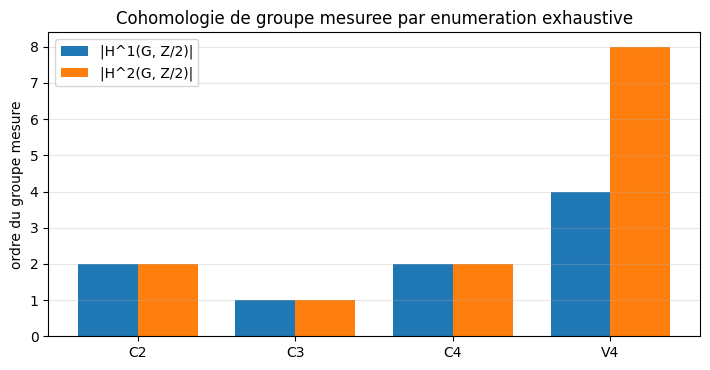

H^1 : {'C2': 2, 'C3': 1, 'C4': 2, 'V4': 4}
H^2 : {'C2': 2, 'C3': 1, 'C4': 2, 'V4': 8}


In [9]:
# Figure de synthese : les ordres des groupes de cohomologie mesures
noms = ["C2", "C3", "C4", "V4"]
h2_mesures = [len(H2[n]) for n in noms]
h1_mesures = [len(H1[n]) for n in noms]

fig, axe = plt.subplots(figsize=(7.2, 3.8))
largeur = 0.38
positions = list(range(len(noms)))
axe.bar([p - largeur / 2 for p in positions], h1_mesures, largeur, label="|H^1(G, Z/2)|")
axe.bar([p + largeur / 2 for p in positions], h2_mesures, largeur, label="|H^2(G, Z/2)|")
axe.set_xticks(positions)
axe.set_xticklabels(noms)
axe.set_ylabel("ordre du groupe mesure")
axe.set_title("Cohomologie de groupe mesuree par enumeration exhaustive")
axe.legend()
axe.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("H^1 :", dict(zip(noms, h1_mesures)))
print("H^2 :", dict(zip(noms, h2_mesures)))

## Exercice 1 — Calculer H²(C₄, Z/3Z)

### Objectif

Mesurer le groupe `H²(C₄, Z/3Z)` par la même méthode, et confronter le résultat à la règle `H²(Cₙ, Z/p) = (Z/p)[n]`.

### Contexte

La section 4 a écrit les fonctions `cocycles_degre2` et `classes_degre2` pour un module `Z/2Z`. Changer le module suffit — mais le nombre de candidats devient `3^16`, et `classes_degre2` doit être relue avec `M = 3`.

### Instructions

1. Calculer `cocycles_degre2(C4, 3, action_triviale)` puis `classes_degre2(..., 3)`.
2. Afficher l'ordre du groupe obtenu et le confronter à `(Z/3)[4]`, c'est-à-dire les éléments de Z/3 tués par 4 (4 est premier avec 3 : ce sous-groupe est donc trivial).
3. Dire si le résultat mesuré confirme la règle.

### Critères de succès

Le groupe `H²(C₄, Z/3Z)` est calculé, son ordre est affiché, et la confrontation à la règle est explicite dans la sortie.

In [10]:
# TODO etudiant : mesurer H^2(C4, Z/3Z) par enumeration exhaustive
def exercice_1():
    """Mesure de H^2(C4, Z/3Z)."""
    # TODO etudiant : enumerer les 2-cocycles sur le module Z/3Z
    resultat = None
    # TODO etudiant : quotienter par les coboundaires et afficher l'ordre du groupe
    return resultat


print("Exercice 1 : a compléter")

Exercice 1 : a compléter


## Exercice 2 — Une action qui rend H¹ non trivial

### Objectif
Calculer `H¹(S₃, Z/4Z)` avec l'action **par le signe**, le comparer à l'action **triviale**
sur le **même** module, et dire ce que la comparaison apprend — y compris si les deux
comptes **coïncident**.

### Contexte
La section 3 a fait le même geste pour C₂. Pour S₃, l'action par le signe envoie les
permutations paires sur l'identité et les impaires sur `m ↦ -m` :
`fabrique_action_signe(S3)` l'implémente. Attention : `Z/4Z` n'est pas de caractéristique 2,
donc `-m ≠ m` en général.

### Instructions
1. Calculer les 1-cocycles de S₃ sur Z/4Z pour l'action par le signe, puis les classes :
   relever `|Z¹|` (nombre de cocycles) et `|B¹|` (nombre de coboundaires **distincts** — c'est
   ce nombre qui entre dans le quotient).
2. Calculer les mêmes deux nombres pour l'action triviale, **sur le même module** Z/4Z (le
   tableau de la section 2 portait sur Z/2Z : il faut le refaire en Z/4Z pour que la
   comparaison soit propre).
3. Comparer les deux quotients `|Z¹| / |B¹|`. Sont-ils égaux, ou distincts ?
   - s'ils sont **égaux**, l'écart ne se lit pas dans le quotient mais dans les **deux termes
     de la fraction** : dire ce que devient chacun des deux termes sous l'autre action
     (lequel change, lequel reste fixe — ou si les deux changent, et dans quel rapport) ;
   - s'ils sont **distincts**, dire quel terme l'action modifie.
4. Chercher l'invariant qui rend compte du résultat : comparer les éléments de `Z/4Z` que
   chaque action **laisse fixes** (tous sous l'action triviale ; les éléments `m` tels que
   `2m = 0` sous le signe — la 2-torsion du module). Est-ce cette différence qui explique
   le comportement des deux termes ?

### Critères de succès
Les quatre nombres (`|Z¹|` et `|B¹|` pour les deux actions) sont affichés, les deux
quotients sont comparés explicitement, et la conclusion porte sur les **termes** de la
fraction — pas sur une différence supposée.

In [11]:
# TODO etudiant : comparer H^1(S3, Z/4Z) pour les actions triviale et signe
def exercice_2():
    """Comparaison des actions triviale et signe sur S3."""
    # TODO etudiant : calculer |H^1(S3, Z/4Z)| pour chacune des deux actions
    resultat = None
    return resultat


print("Exercice 2 : a compléter")

Exercice 2 : a compléter


## Exercice 3 — Classifier une extension centrale de V₄

### Objectif

Montrer, par la mesure, que `H²(V₄, Z/2)` ne classe **pas** un unique groupe d'ordre 8 : la section 4 a mesuré `|H²(V₄, Z/2)| = 8`, et l'exercice consiste à comprendre ce que cela signifie.

### Contexte

Pour C₂, chaque classe de H² correspondait à un groupe d'ordre 4 construit par la formule `(m, g) . (m', g') = (m + m' + f(g, g'), g + g')`. Pour V₄, la même construction donne des groupes d'ordre 8 — et il y en a **plusieurs** non isomorphes. Les groupes d'ordre 8 sont en nombre fixe : `C₈`, `C₄ × C₂`, `C₂ × C₂ × C₂`, `D₄`, `Q₈`. Mais **tous ne sont pas** des extensions centrales de V₄ par Z/2 : le quotient par le noyau doit être V₄. La question de l'exercice est de déterminer lesquels la construction produit effectivement.

### Instructions

1. Reprendre la construction de la section 5 avec V₄ et un représentant de chaque classe de `H²(V₄, Z/2)` (il y en a 8) — prendre les représentants fournis par `classes_degre2`, pour lesquels `(0, e)` est bien l'élément neutre.
2. Pour chaque extension, calculer l'ordre des éléments et dire quels groupes d'ordre 8 apparaissent — et écarter ceux qui ne peuvent pas être une extension centrale de V₄ par Z/2.
3. Conclure : une classe de cohomologie correspond-elle à un groupe, ou à une **famille** de groupes ? Justifier par les mesures.

### Critères de succès

Les extensions sont construites, leurs ordres d'éléments sont mesurés, et la conclusion sur le grain de la classification est argumentée par les nombres.

In [12]:
# TODO etudiant : construire les extensions centrales de V4 et classer les groupes obtenus
def exercice_3():
    """Extensions centrales de V4 par Z/2, classees par H^2(V4, Z/2)."""
    # TODO etudiant : construire une extension par classe de H^2 et en mesurer les ordres
    resultat = None
    return resultat


print("Exercice 3 : a compléter")

Exercice 3 : a compléter


## Synthèse des apprentissages

### Technologies exploitées

- Python stdlib : `itertools.product` pour l'énumération exhaustive des cocycles, structures de données maison pour les groupes finis
- matplotlib pour la figure de synthèse
- aucune dépendance externe : le sujet *est* l'algèbre, l'outil est l'énumération

### Bonnes pratiques identifiées

- **énumérer plutôt que supposer** : chaque nombre affiché sort d'une liste finie explicitement construite, jamais d'une formule récitée
- **un contrôle négatif par résultat** : C₃ et V₄ réfutent la règle naïve du degré 2
- **deux chemins de calcul pour le même objet** : cocycles d'un côté, sous-groupes d'indice 2 et UCT de l'autre
- **la mesure avant la théorie** : dans la section 5, c'est l'ordre des éléments qui identifie C₄ et C₂ × C₂, pas un théorème cité

### Limitations

- l'énumération exhaustive devient inexploitable au-delà de `|G| = 4` (le nombre de candidats croît comme `|M|^(|G|²)`) : au-delà, il faut la résolution standard des groupes, hors périmètre de ce carnet
- H¹ et H² ne suffisent pas à classer les extensions : pour V₄, une classe de H² correspond à une famille de groupes, pas à un groupe
- le module Z/nZ trivial est le plus simple ; les modules non triviaux n'apparaissent qu'en fin de carnet

### Extensions possibles

- calculer `H²(G, Z/n)` pour `n = 3, 4` et confirmer la formule `|H²(Cₙ, Z/p)|` pour `p` impair
- calculer le multiplicateur de Schur `H²(G, Z)` par une résolution, et le comparer aux valeurs obtenues ici par interpolation
- étendre la méthode à un module d'anneau (et non de groupe fini), où les coboundaires deviennent des matrices

In [13]:
# Recapitulatif de fin de session
print("=" * 62)
print("RECAPITULATIF")
print("=" * 62)
for nom in ("C2", "C3", "C4", "V4"):
    print("%-4s : |H^1(Z/2)| = %d   |H^2(Z/2)| = %d"
          % (nom, len(H1[nom]), len(H2[nom])))
print()
print("Controle negatif : |H^2(C3, Z/2)| = %d  (trivial) alors que |H^2(C2, Z/2)| = %d"
      % (len(H2["C3"]), len(H2["C2"])))
print("Les 3 exercices restent a completer (stubs C.1, non bloquants).")

RECAPITULATIF
C2   : |H^1(Z/2)| = 2   |H^2(Z/2)| = 2
C3   : |H^1(Z/2)| = 1   |H^2(Z/2)| = 1
C4   : |H^1(Z/2)| = 2   |H^2(Z/2)| = 2
V4   : |H^1(Z/2)| = 4   |H^2(Z/2)| = 8

Controle negatif : |H^2(C3, Z/2)| = 1  (trivial) alors que |H^2(C2, Z/2)| = 2
Les 3 exercices restent a completer (stubs C.1, non bloquants).
